
RESULTADOS DEL EXPERIMENTO
               Etapa  Cantidad Conversion_etapa Abandono_etapa Conversion_global
          Visitantes     10000              NaN            NaN           100.00%
   Consulta producto      6048           60.48%         39.52%            60.48%
Agregaron al carrito      2101           34.74%         65.26%            21.01%
  Iniciaron checkout      1477           70.30%         29.70%            14.77%
           Compraron       747           50.58%         49.42%             7.47%

Conversión global:
7.47%

Compras generadas:
747


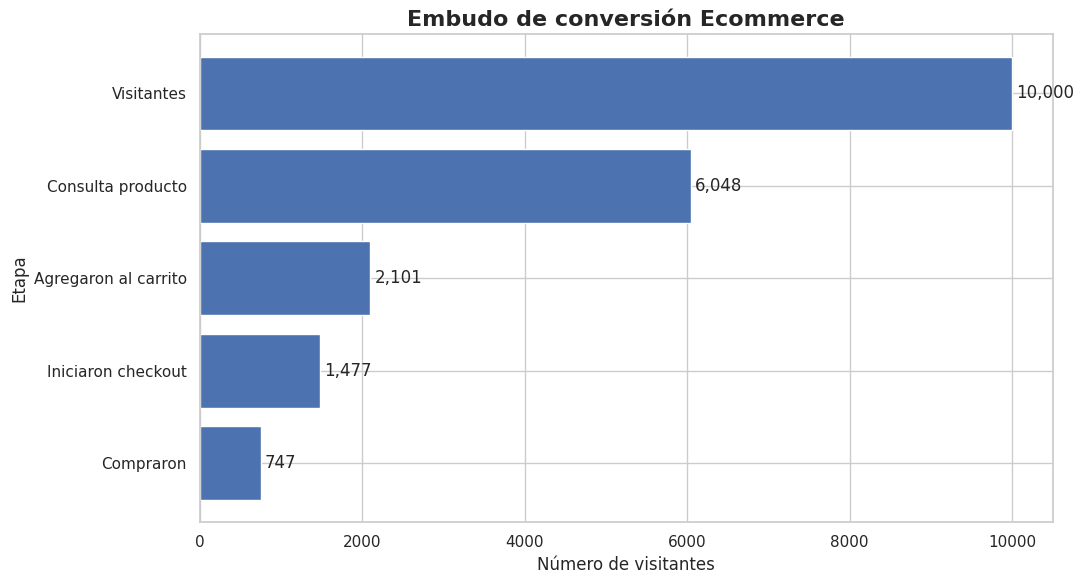

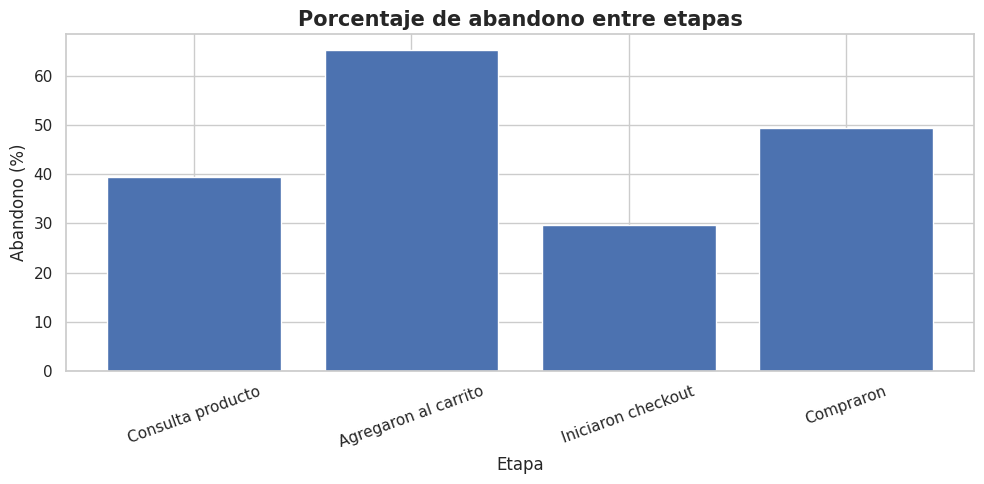


COMPARACIÓN DE ESCENARIOS
Compras originales: 747
Compras escenario mejorado: 943
Incremento de compras: 196
Mejora porcentual: 26.24%

Archivos generados en: /content/resultados_ecommerce


In [ ]:
# ============================================================
# LABORATORIO DE DATOS
# EXPERIMENTO #001: EMBUDO DE CONVERSIÓN ECOMMERCE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

SEED = 42
N_VISITANTES = 10_000

rng = np.random.default_rng(SEED)

OUTPUT_DIR = Path("resultados_ecommerce")
OUTPUT_DIR.mkdir(exist_ok=True)

# Probabilidades hipotéticas de conversión
PROB_PRODUCTO = 0.60
PROB_CARRITO = 0.35
PROB_CHECKOUT = 0.70
PROB_COMPRA = 0.50


# ------------------------------------------------------------
# 2. GENERACIÓN DE VISITANTES
# ------------------------------------------------------------

df = pd.DataFrame({
    "visitor_id": np.arange(1, N_VISITANTES + 1)
})

# Todos los visitantes ingresan a la tienda
df["visit"] = 1

# ------------------------------------------------------------
# 3. SIMULACIÓN DEL EMBUDO
# ------------------------------------------------------------

# Etapa 1: consulta de producto
df["product_view"] = (
    rng.random(N_VISITANTES) < PROB_PRODUCTO
).astype(int)

# Etapa 2: agregar al carrito
df["add_to_cart"] = (
    (df["product_view"] == 1) &
    (rng.random(N_VISITANTES) < PROB_CARRITO)
).astype(int)

# Etapa 3: iniciar checkout
df["checkout"] = (
    (df["add_to_cart"] == 1) &
    (rng.random(N_VISITANTES) < PROB_CHECKOUT)
).astype(int)

# Etapa 4: completar compra
df["purchase"] = (
    (df["checkout"] == 1) &
    (rng.random(N_VISITANTES) < PROB_COMPRA)
).astype(int)


# ------------------------------------------------------------
# 4. CONSTRUIR TABLA DEL EMBUDO
# ------------------------------------------------------------

stages = {
    "Visitantes": "visit",
    "Consulta producto": "product_view",
    "Agregaron al carrito": "add_to_cart",
    "Iniciaron checkout": "checkout",
    "Compraron": "purchase"
}

funnel = []

previous_count = None

for stage_name, column in stages.items():

    count = int(df[column].sum())

    conversion = (
        count / previous_count
        if previous_count is not None and previous_count > 0
        else np.nan
    )

    dropoff = (
        1 - conversion
        if not np.isnan(conversion)
        else np.nan
    )

    funnel.append({
        "Etapa": stage_name,
        "Cantidad": count,
        "Conversion_etapa": conversion,
        "Abandono_etapa": dropoff
    })

    previous_count = count

funnel_df = pd.DataFrame(funnel)

# Conversión global respecto a visitantes
conversion_global = (
    funnel_df.loc[4, "Cantidad"] /
    funnel_df.loc[0, "Cantidad"]
)

funnel_df["Conversion_global"] = (
    funnel_df["Cantidad"] /
    funnel_df.loc[0, "Cantidad"]
)


# ------------------------------------------------------------
# 5. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("RESULTADOS DEL EXPERIMENTO")
print("=" * 60)

print(funnel_df.to_string(
    index=False,
    formatters={
        "Conversion_etapa": lambda x: (
            f"{x:.2%}" if pd.notna(x) else "-"
        ),
        "Abandono_etapa": lambda x: (
            f"{x:.2%}" if pd.notna(x) else "-"
        ),
        "Conversion_global": lambda x: f"{x:.2%}"
    }
))

print("\nConversión global:")
print(f"{conversion_global:.2%}")

print("\nCompras generadas:")
print(funnel_df.iloc[-1]["Cantidad"])


# ------------------------------------------------------------
# 6. VISUALIZACIÓN DEL EMBUDO
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 6))

labels = funnel_df["Etapa"]
values = funnel_df["Cantidad"]

bars = ax.barh(labels, values)

ax.invert_yaxis()

ax.set_title(
    "Embudo de conversión Ecommerce",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Número de visitantes")
ax.set_ylabel("Etapa")

for bar, value in zip(bars, values):

    ax.text(
        bar.get_width() + 50,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,}",
        va="center"
    )

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "embudo_conversion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. VISUALIZAR ABANDONO POR ETAPA
# ------------------------------------------------------------

abandonment_df = funnel_df.iloc[1:].copy()

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    abandonment_df["Etapa"],
    abandonment_df["Abandono_etapa"] * 100
)

ax.set_title(
    "Porcentaje de abandono entre etapas",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Abandono (%)")
ax.set_xlabel("Etapa")

ax.tick_params(axis="x", rotation=20)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "abandono_por_etapa.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. SIMULACIÓN DE UNA MEJORA
# ------------------------------------------------------------

# Escenario original
compras_originales = int(df["purchase"].sum())

# Mejoramos checkout -> compra:
# pasa del 50% al 65%

PROB_COMPRA_MEJORADA = 0.65

# Mantenemos los mismos visitantes que llegaron a checkout
# para comparar ambos escenarios.

checkout_mask = df["checkout"] == 1

compras_mejoradas = int(
    (
        rng.random(checkout_mask.sum())
        < PROB_COMPRA_MEJORADA
    ).sum()
)

incremento = compras_mejoradas - compras_originales

print("\n" + "=" * 60)
print("COMPARACIÓN DE ESCENARIOS")
print("=" * 60)

print(f"Compras originales: {compras_originales:,}")
print(f"Compras escenario mejorado: {compras_mejoradas:,}")
print(f"Incremento de compras: {incremento:,}")

if compras_originales > 0:

    mejora_porcentual = (
        incremento / compras_originales
    ) * 100

    print(f"Mejora porcentual: {mejora_porcentual:.2f}%")


# ------------------------------------------------------------
# 9. EXPORTAR RESULTADOS
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_DIR / "visitantes_ecommerce.csv",
    index=False
)

funnel_df.to_csv(
    OUTPUT_DIR / "resumen_embudo.csv",
    index=False
)

print("\nArchivos generados en:", OUTPUT_DIR.resolve())